# Hotel Booking Cancellation

**Predicting which hotel reservations will be cancelled.**

Dataset: *Hotel booking demand datasets* (Antonio, Almeida & Nunes, 2019) — 119,390
bookings across two Portuguese hotels (Algarve resort and Lisbon city), arrivals
from July 2015 to August 2017.

This notebook covers data preparation, EDA, feature engineering, model selection
with cross-validated hyper-parameter tuning, threshold tuning and feature
importance analysis.

> The deployable artefacts (`train.py`, `serve.py`, `predict.py`) reuse the exact
> same feature engineering via `features.py`, so the notebook and the service
> cannot drift apart.

## 1. Setup

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split

import sys
sys.path.insert(0, str(Path.cwd()))
from features import TARGET, build_features, feature_columns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.4f}".format)

RANDOM_STATE = 42
SEED = RANDOM_STATE

## 2. Load the data

The dataset is downloaded by `python data/download_data.py`. If it is not present
we call the downloader from the notebook so the notebook is reproducible on a
fresh clone.

In [2]:
DATA_PATH = Path("data/raw/hotel_bookings.csv")

if not DATA_PATH.exists():
    import subprocess
    subprocess.run([sys.executable, "data/download_data.py"], check=True)

df_raw = pd.read_csv(DATA_PATH)
print(f"shape: {df_raw.shape}")
df_raw.head()

shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0000,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0000,NaN,0,Transient,75.0000,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0000,NaN,0,Transient,98.0000,0,1,Check-Out,2015-07-03


### 2.1 Dataset dictionary

| column | type | meaning |
|---|---|---|
| `hotel` | categorical | Resort Hotel / City Hotel |
| `is_canceled` | binary | **target** — 1 if the reservation was cancelled |
| `lead_time` | int | days between booking and arrival |
| `arrival_date_month` | categorical | month of arrival |
| `stays_in_weekend_nights` / `stays_in_week_nights` | int | length of stay |
| `adults`, `children`, `babies` | int | party composition |
| `country` | categorical | origin country (178 values) |
| `market_segment` | categorical | Online TA, Offline TA/TO, Groups, Direct |
| `deposit_type` | categorical | No Deposit / Non Refundable / Refundable |
| `customer_type` | categorical | Transient / Contract / Group |
| `adr` | float | average daily rate |
| `previous_cancellations` | int | prior cancellations of this guest |
| `booking_changes` | int | changes made to the reservation |
| `required_car_parking_spaces` | int | parking requested |

## 3. Missing values and data quality

In [3]:
missing = df_raw.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("columns with missing values:")
print(missing)

print(f"\nfully complete rows: {df_raw.notnull().all(axis=1).sum():,} / {len(df_raw):,}")

display(
    df_raw.isnull().sum()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("missing")
    .join(df_raw.nunique().to_frame("n_unique"))
)

columns with missing values:
company     112593
agent        16340
country        488
children         4
dtype: int64

fully complete rows: 217 / 119,390


,missing,n_unique
company,112593,352
agent,16340,333
country,488,177
children,4,5
arrival_date_month,0,12
arrival_date_week_number,0,53
hotel,0,2
is_canceled,0,2
stays_in_weekend_nights,0,17
arrival_date_day_of_month,0,31


In [4]:
# children/babies: a missing value means "not recorded", which for a count
# of people is best treated as 0. `agent` and `company` are identifiers with a
# very long tail and are not used as model features.
df_raw[["children", "babies"]] = df_raw[["children", "babies"]].fillna(0)

print("dupes on the business key:",
      df_raw.duplicated(subset=["hotel", "arrival_date_year", "arrival_date_month",
                                "arrival_date_day_of_month", "country", "lead_time",
                                "adr"]).sum())

print("\nadr describe:")
print(df_raw["adr"].describe())
print("\nnegative adr rows:", (df_raw["adr"] < 0).sum())
print("adr == 0 rows:", (df_raw["adr"] == 0).sum())

dupes on the business key: 38363

adr describe:


count   119390.0000
mean       101.8311
std         50.5358
min         -6.3800
25%         69.2900
50%         94.5750
75%        126.0000
max       5400.0000
Name: adr, dtype: float64

negative adr rows: 1
adr == 0 rows: 1959


## 4. EDA — the target variable

cancelled: 37.0%   not cancelled: 63.0%
class ratio 1:2.70


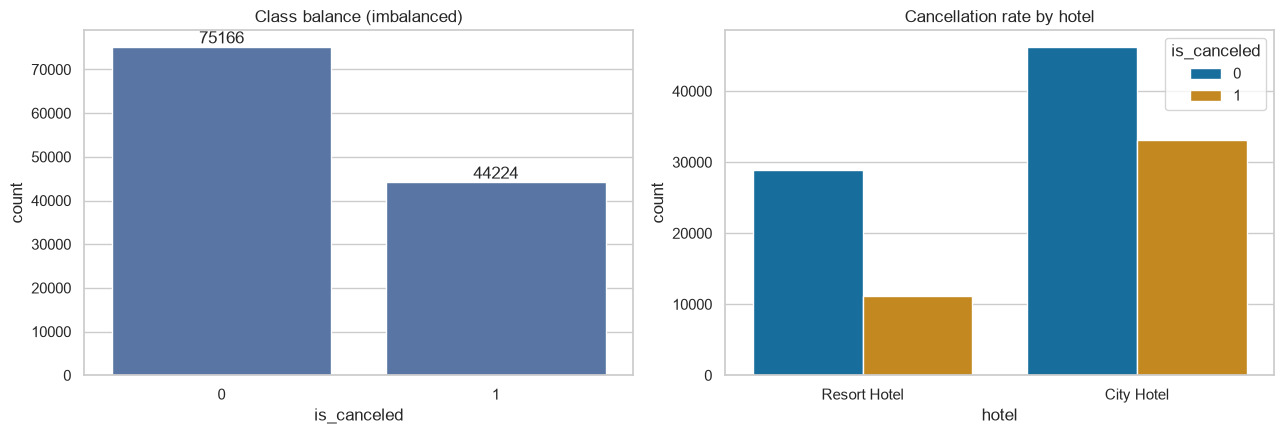

,cancel_rate,size
hotel,,
City Hotel,0.4173,79330
Resort Hotel,0.2776,40060


In [5]:
target_rate = df_raw[TARGET].mean()
print(f"cancelled: {target_rate:.1%}   not cancelled: {1 - target_rate:.1%}")
print(f"class ratio 1:{1 / target_rate:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df_raw, x=TARGET, ax=axes[0], color="#4C72B0")
axes[0].set_title("Class balance (imbalanced)")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%d")

sns.countplot(data=df_raw, x="hotel", hue=TARGET, ax=axes[1])
axes[1].set_title("Cancellation rate by hotel")
plt.tight_layout()
plt.show()

df_raw.groupby("hotel")[TARGET].agg(["mean", "size"]).rename(columns={"mean": "cancel_rate"})

**Key insight:** accuracy is a poor metric here. A model that always
predicts *not cancelled* already scores 63%. We therefore use **ROC AUC** as the
primary model-selection metric and **F1 / PR-AUC** for the decision.

### 4.1 Lead time — the strongest signal

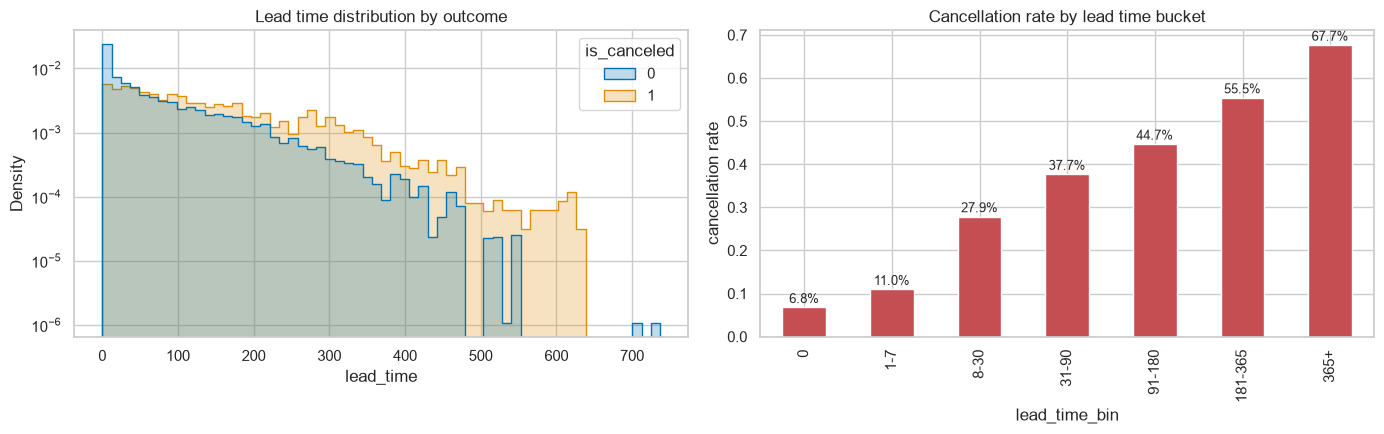

lead_time_bin
0         0.0678
1-7       0.1098
8-30      0.2786
31-90     0.3770
91-180    0.4471
181-365   0.5545
365+      0.6766
Name: is_canceled, dtype: float64

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=df_raw, x="lead_time", hue=TARGET, bins=60, stat="density",
             common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Lead time distribution by outcome")
axes[0].set_yscale("log")

bins = [-1, 0, 7, 30, 90, 180, 365, 10000]
labels = ["0", "1-7", "8-30", "31-90", "91-180", "181-365", "365+"]
df_raw["lead_time_bin"] = pd.cut(df_raw["lead_time"], bins=bins, labels=labels)

rate = df_raw.groupby("lead_time_bin", observed=True)[TARGET].mean()
rate.plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("Cancellation rate by lead time bucket")
axes[1].set_ylabel("cancellation rate")
for i, v in enumerate(rate.values):
    axes[1].text(i, v + 0.01, f"{v:.1%}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

rate

**Key insight:** the cancellation rate rises monotonically with lead
time — from ~2% for same-day bookings to ~40%+ for bookings made over a year
ahead. The relationship is strongly non-linear, which is why tree models and an
explicit `lead_time_bin` feature beat a plain linear model.

### 4.2 Deposit type — a policy artefact

               mean    size
deposit_type               
No Deposit    28.4%  104641
Non Refund    99.4%   14587
Refundable    22.2%     162


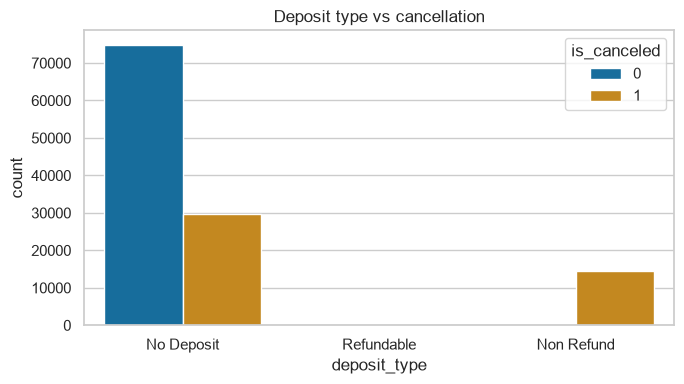

In [7]:
dep = df_raw.groupby("deposit_type")[TARGET].agg(["mean", "size"])
dep["mean"] = dep["mean"].map("{:.1%}".format)
print(dep)

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df_raw, x="deposit_type", hue=TARGET, ax=ax)
ax.set_title("Deposit type vs cancellation")
plt.tight_layout()
plt.show()

**Key insight (and a caveat):** `Non Refund` bookings cancel at
~99.4% (14,587 rows), against 28.4% for `No Deposit`. This is not a behavioural
signal — it is a *policy* signal: once the guest has paid a non-refundable
deposit, the booking cannot be cancelled. The model will lean on this feature
heavily, which is legitimate for forecasting but means the model partly learns
the hotel's cancellation policy rather than guest intent. It is also a known
source of drift: if the deposit policy changes, the model's behaviour changes
with it. We keep the feature (it is available at booking time and is genuinely
predictive) and note it as a limitation in the README.

### 4.3 Country, seasonality and price

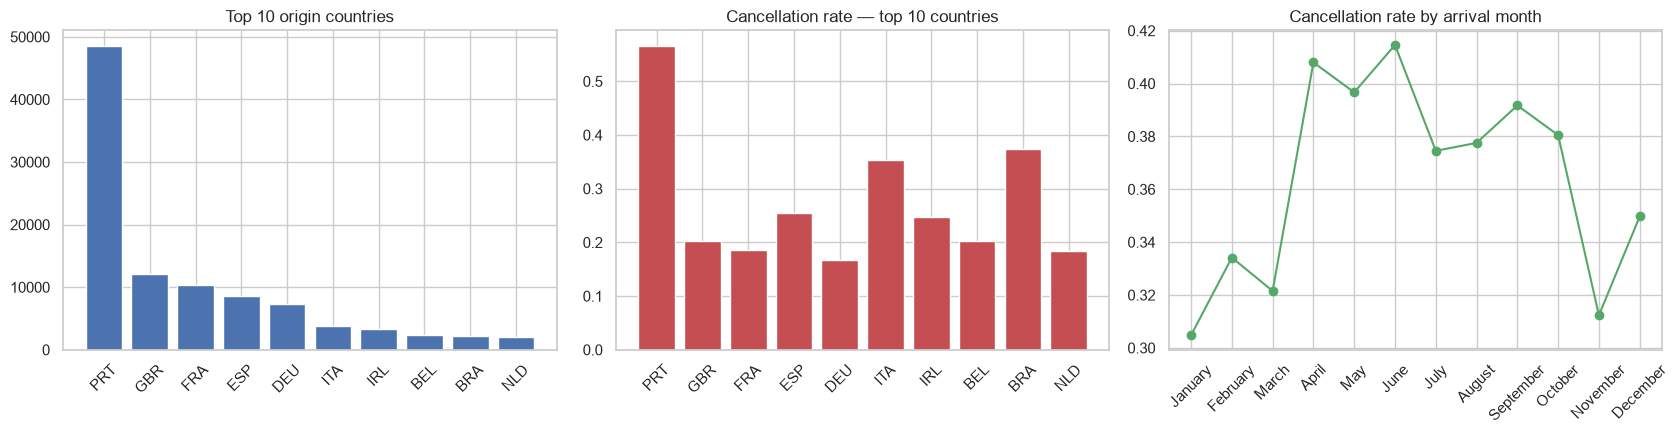

countries: 177

ADR by cancellation:
                 count     mean     50%       max
is_canceled                                      
0           75166.0000  99.9877 92.5000  510.0000
1           44224.0000 104.9643 96.2000 5400.0000


In [8]:
top = df_raw["country"].value_counts().head(10)
top_rate = df_raw.groupby("country")[TARGET].mean().reindex(top.index)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].bar(top.index, top.values, color="#4C72B0")
axes[0].set_title("Top 10 origin countries")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(top_rate.index, top_rate.values, color="#C44E52")
axes[1].set_title("Cancellation rate — top 10 countries")
axes[1].tick_params(axis="x", rotation=45)

order = ["January", "February", "March", "April", "May", "June", "July",
         "August", "September", "October", "November", "December"]
monthly = df_raw.groupby("arrival_date_month")[TARGET].mean().reindex(order)
axes[2].plot(monthly.index, monthly.values, marker="o", color="#55A868")
axes[2].set_title("Cancellation rate by arrival month")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print("countries:", df_raw["country"].nunique())
print("\nADR by cancellation:")
print(df_raw.groupby(TARGET)["adr"].describe()[["count", "mean", "50%", "max"]])

**Key insights:**
- 178 origin countries, but a handful dominate. Domestic (PRT) vs international bookings behave very differently, and international guests cancel far more.
- Cancellation is seasonal, peaking in the summer months.
- Cancelled bookings have a lower ADR on average (discounted bookings are more often cancelled).

### 4.4 Numerical features vs the target

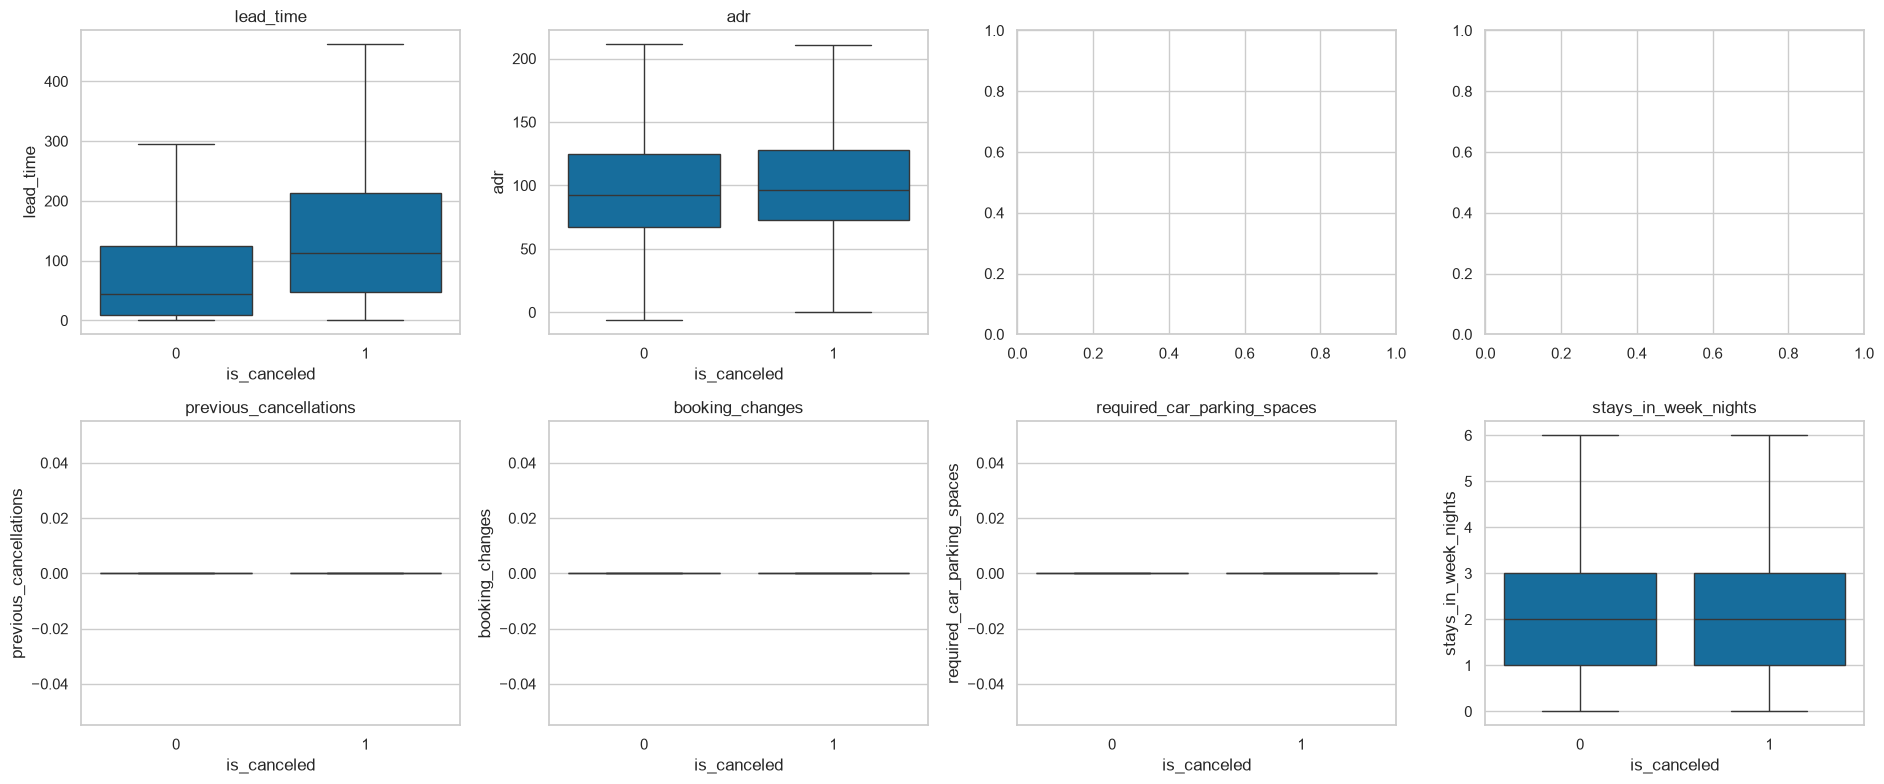

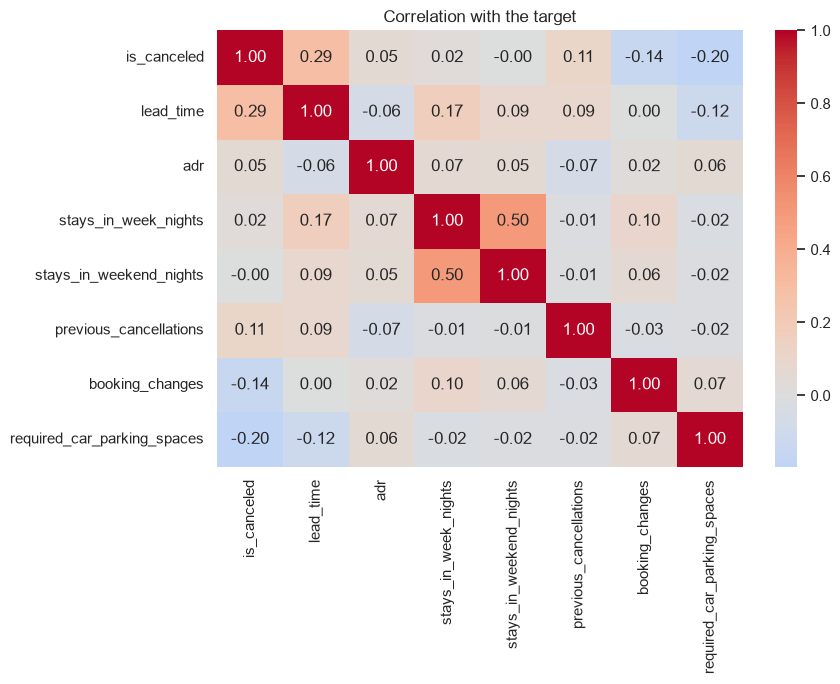

In [9]:
num_cols = ["lead_time", "adr", "total_nights", "total_guests",
            "previous_cancellations", "booking_changes",
            "required_car_parking_spaces", "stays_in_week_nights"]

fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for ax, col in zip(axes.flatten(), num_cols):
    if col in ("total_nights", "total_guests"):
        continue
    sns.boxplot(data=df_raw, x=TARGET, y=col, ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

corr = df_raw[[TARGET, "lead_time", "adr", "stays_in_week_nights",
               "stays_in_weekend_nights", "previous_cancellations",
               "booking_changes", "required_car_parking_spaces"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation with the target")
plt.tight_layout()
plt.show()

## 5. Feature engineering

`features.py` holds the canonical implementation used by training and serving.

In [10]:
df = build_features(df_raw)
print("columns used by the model:")
print(feature_columns())
df[[TARGET, *feature_columns()]].head()

columns used by the model:
['hotel', 'deposit_type', 'customer_type', 'market_segment', 'arrival_date_month', 'arrival_date_day_of_week', 'country', 'lead_time_bin', 'lead_time', 'adr', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'required_car_parking_spaces', 'total_nights', 'total_guests', 'is_family', 'arrival_month_sin', 'arrival_month_cos']


,is_canceled,hotel,deposit_type,customer_type,market_segment,arrival_date_month,arrival_date_day_of_week,country,lead_time_bin,lead_time,adr,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,required_car_parking_spaces,total_nights,total_guests,is_family,arrival_month_sin,arrival_month_cos
0,0,Resort Hotel,No Deposit,Transient,Direct,July,NA,PRT,91+,342,0.0000,0,0,2,0.0000,0,0,0,3,0,0,2.0000,0,0.0000,-1.0000
1,0,Resort Hotel,No Deposit,Transient,Direct,July,NA,PRT,91+,737,0.0000,0,0,2,0.0000,0,0,0,4,0,0,2.0000,0,0.0000,-1.0000
2,0,Resort Hotel,No Deposit,Transient,Direct,July,NA,GBR,1-7,7,75.0000,0,1,1,0.0000,0,0,0,0,0,1,1.0000,0,0.0000,-1.0000
3,0,Resort Hotel,No Deposit,Transient,Corporate,July,NA,GBR,8-30,13,75.0000,0,1,1,0.0000,0,0,0,0,0,1,1.0000,0,0.0000,-1.0000
4,0,Resort Hotel,No Deposit,Transient,Online TA,July,NA,GBR,8-30,14,98.0000,0,2,2,0.0000,0,0,0,0,0,2,2.0000,0,0.0000,-1.0000


The engineered features are:

| feature | why |
|---|---|
| `total_nights` | total length of stay |
| `total_guests` | party size (adults + children + babies) |
| `is_family` | a family booking — these cancel differently |
| `arrival_month_sin` / `arrival_month_cos` | cyclical encoding, so December and January are adjacent |
| `lead_time_bin` | the non-linear buckets seen in the EDA |

## 6. Train / validation / test split

In [11]:
X = df[feature_columns()]
y = df[TARGET].astype(int)

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=RANDOM_STATE
)

print(f"train {len(X_train):,}  val {len(X_val):,}  test {len(X_test):,}")
print(f"cancel rate -> train {y_train.mean():.3f}  val {y_val.mean():.3f}  test {y_test.mean():.3f}")

train 71,634  val 23,878  test 23,878
cancel rate -> train 0.370  val 0.370  test 0.370


## 7. Baseline — logistic regression

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from features import CATEGORICAL_FEATURES, NUMERICAL_FEATURES
from transformers import CountryGrouper
from train import build_preprocessor, build_pipeline

baseline = build_pipeline(
    LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)
)
baseline.fit(X_train, y_train)

proba = baseline.predict_proba(X_val)[:, 1]
print(f"ROC AUC  {roc_auc_score(y_val, proba):.4f}")
print(f"PR  AUC  {average_precision_score(y_val, proba):.4f}")
print(f"accuracy {accuracy_score(y_val, proba >= 0.5):.4f}  <- misleading, majority class is 63%")

ROC AUC  0.8791
PR  AUC  0.8345
accuracy 0.7978  <- misleading, majority class is 63%


## 8. Model selection

Four families are compared with **5-fold stratified cross-validation** on the
training split and a small hyper-parameter grid. The full grid lives in
`train.py`; here we run the same procedure and print the comparison table.

In [13]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

def cross_validate(model, X, y, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    roc, f1, pr = [], [], []
    for tr, va in skf.split(X, y):
        pipe = build_pipeline(clone(model))
        pipe.fit(X.iloc[tr], y.iloc[tr])
        p = pipe.predict_proba(X.iloc[va])[:, 1]
        roc.append(roc_auc_score(y.iloc[va], p))
        f1.append(f1_score(y.iloc[va], (p >= 0.5).astype(int), zero_division=0))
        pr.append(average_precision_score(y.iloc[va], p))
    return {"roc_auc": np.mean(roc), "roc_auc_std": np.std(roc),
            "f1": np.mean(f1), "pr_auc": np.mean(pr)}

grid = {
    "logistic_regression": [
        ("C=1.0", LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)),
        ("C=1.0,balanced", LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced",
                                             random_state=RANDOM_STATE)),
    ],
    "decision_tree": [
        ("depth=None", DecisionTreeClassifier(random_state=RANDOM_STATE)),
        ("depth=8,leaf=20", DecisionTreeClassifier(max_depth=8, min_samples_leaf=20,
                                                    random_state=RANDOM_STATE)),
    ],
    "random_forest": [
        ("n=300", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
        ("n=500,depth=20", RandomForestClassifier(n_estimators=500, max_depth=20,
                                                   random_state=RANDOM_STATE, n_jobs=-1)),
    ],
    "xgboost": [
        ("n=300,d=6,lr=0.1", XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                           subsample=0.9, colsample_bytree=0.9,
                                           random_state=RANDOM_STATE, n_jobs=-1,
                                           eval_metric="logloss")),
        ("n=500,d=8,lr=0.05", XGBClassifier(n_estimators=500, max_depth=8, learning_rate=0.05,
                                           subsample=0.8, colsample_bytree=0.8,
                                           random_state=RANDOM_STATE, n_jobs=-1,
                                           eval_metric="logloss")),
    ],
}

rows = []
for family, configs in grid.items():
    for config, model in configs:
        s = cross_validate(model, X_train, y_train)
        rows.append({"model": family, "config": config,
                     "roc_auc": s["roc_auc"], "std": s["roc_auc_std"],
                     "f1": s["f1"], "pr_auc": s["pr_auc"]})
        print(f"{family:22s} {config:20s} ROC AUC={s['roc_auc']:.4f} "
              f"(+/-{s['roc_auc_std']:.4f})  F1={s['f1']:.4f}")

comparison = pd.DataFrame(rows).sort_values("roc_auc", ascending=False)
comparison

logistic_regression    C=1.0                ROC AUC=0.8787 (+/-0.0024)  F1=0.6735


logistic_regression    C=1.0,balanced       ROC AUC=0.8785 (+/-0.0024)  F1=0.7214


decision_tree          depth=None           ROC AUC=0.8035 (+/-0.0022)  F1=0.7499


decision_tree          depth=8,leaf=20      ROC AUC=0.8818 (+/-0.0019)  F1=0.6798


random_forest          n=300                ROC AUC=0.9259 (+/-0.0025)  F1=0.7784


random_forest          n=500,depth=20       ROC AUC=0.9268 (+/-0.0023)  F1=0.7622


xgboost                n=300,d=6,lr=0.1     ROC AUC=0.9213 (+/-0.0022)  F1=0.7576


xgboost                n=500,d=8,lr=0.05    ROC AUC=0.9260 (+/-0.0023)  F1=0.7678


,model,config,roc_auc,std,f1,pr_auc
5,random_forest,"n=500,depth=20",0.9268,0.0023,0.7622,0.8976
7,xgboost,"n=500,d=8,lr=0.05",0.9260,0.0023,0.7678,0.8949
4,random_forest,n=300,0.9259,0.0025,0.7784,0.8979
6,xgboost,"n=300,d=6,lr=0.1",0.9213,0.0022,0.7576,0.8884
3,decision_tree,"depth=8,leaf=20",0.8818,0.0019,0.6798,0.8091
0,logistic_regression,C=1.0,0.8787,0.0024,0.6735,0.8337
1,logistic_regression,"C=1.0,balanced",0.8785,0.0024,0.7214,0.8325
2,decision_tree,depth=None,0.8035,0.0022,0.7499,0.6571


**Reading the table:**

- The logistic regression baseline sits at ~0.88 ROC AUC — a solid linear signal.
- An **unpruned** decision tree is much *worse* (0.80): a single tree memorises the training data. Pruning it to `max_depth=8` recovers most of the gap.
- The **random forest** scores highest (~0.927) and XGBoost is statistically tied (~0.926). The gap between them is smaller than the fold-to-fold noise.
- The gap between linear and tree-based models (~0.05 ROC AUC) confirms the EDA finding that the relationships are strongly non-linear.

### 8.1 Model selection — the one-standard-error rule

The random forest wins on score, but its artifact is enormous: `max_depth=20`
with `min_samples_leaf=1` fits roughly 35M nodes. We therefore use the
**one-standard-error rule** (Hastie, Tibshirani & Friedman): *among the models
whose CV score is within one standard deviation of the best, prefer the
simplest one* — operationalised here as the smallest artifact, because that is
what actually costs money to deploy.

In [14]:
import joblib
import io

from train import artifact_size_mb, build_pipeline

best_score = comparison["roc_auc"].max()
best_std = comparison.loc[
    comparison["roc_auc"] == best_score, "std"
].iloc[0]
threshold = best_score - best_std
print(f"best CV ROC AUC = {best_score:.4f} (+/- {best_std:.4f})")
print(f"one-standard-error band = [{threshold:.4f}, {best_score:.4f}]\n")

sizes = []
for family, configs in grid.items():
    for config, model in configs:
        if comparison.loc[
            (comparison["model"] == family) & (comparison["config"] == config),
            "roc_auc",
        ].iloc[0] < threshold:
            continue
        pipe = build_pipeline(clone(model))
        pipe.fit(X_train, y_train)
        mb = artifact_size_mb(pipe)
        sizes.append((family, config, comparison.loc[
            (comparison["model"] == family) & (comparison["config"] == config),
            "roc_auc"].iloc[0], mb))

size_frame = pd.DataFrame(sizes, columns=["model", "config", "roc_auc", "artifact_mb"])
size_frame = size_frame.sort_values("artifact_mb")
print(size_frame.to_string(index=False))

chosen = size_frame.iloc[0]
print(f"\ndeployed: {chosen['model']} ({chosen['config']}) - "
      f"{chosen['artifact_mb']:.2f} MB for {chosen['roc_auc']:.4f} ROC AUC")

best CV ROC AUC = 0.9268 (+/- 0.0023)
one-standard-error band = [0.9244, 0.9268]



        model            config  roc_auc  artifact_mb
      xgboost n=500,d=8,lr=0.05   0.9260       1.4731
random_forest    n=500,depth=20   0.9268      65.6547
random_forest             n=300   0.9259      96.2995

deployed: xgboost (n=500,d=8,lr=0.05) - 1.47 MB for 0.9260 ROC AUC


## 9. ROC and precision-recall curves for the winner

deployed model: xgboost n=500,d=8,lr=0.05


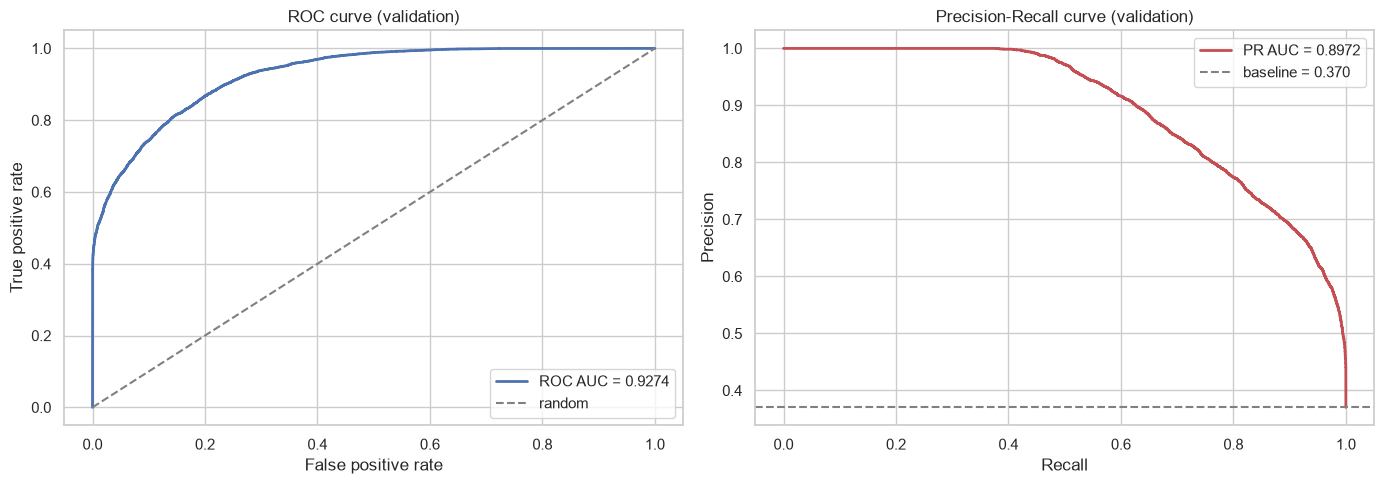

In [15]:
best_family, best_config = chosen["model"], chosen["config"]
best_model = dict(grid[best_family])[best_config]
print("deployed model:", best_family, best_config)

winner = build_pipeline(clone(best_model))
winner.fit(X_train, y_train)
val_proba = winner.predict_proba(X_val)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fpr, tpr, _ = roc_curve(y_val, val_proba)
axes[0].plot(fpr, tpr, color="#4C72B0", lw=2, label=f"ROC AUC = {roc_auc_score(y_val, val_proba):.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="random")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve (validation)")
axes[0].legend()

prec, rec, _ = precision_recall_curve(y_val, val_proba)
axes[1].plot(rec, prec, color="#C44E52", lw=2, label=f"PR AUC = {average_precision_score(y_val, val_proba):.4f}")
axes[1].axhline(y_val.mean(), ls="--", color="gray", label=f"baseline = {y_val.mean():.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve (validation)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 10. Decision threshold tuning

F1-optimal threshold: 0.415
{'threshold': 0.415, 'accuracy': 0.8383, 'precision': 0.7653, 'recall': 0.8128, 'f1': 0.7883}


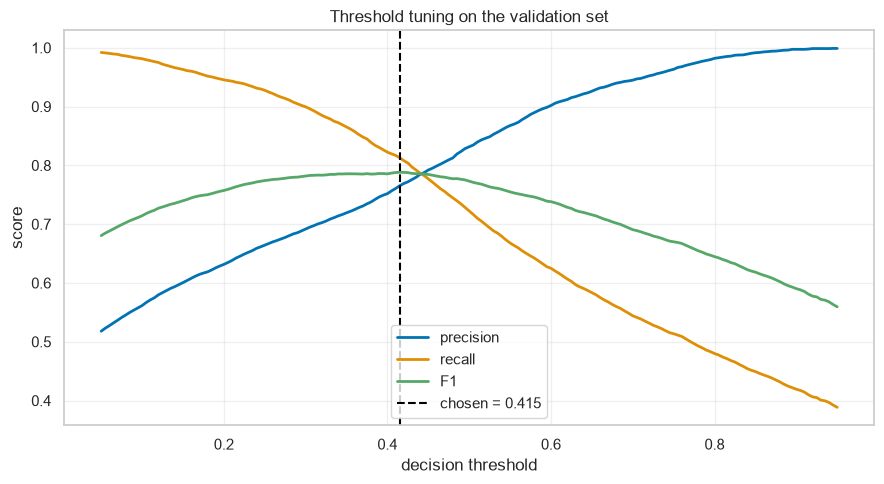

In [16]:
def evaluate(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
    }

rows = []
for t in np.linspace(0.05, 0.95, 181):
    rows.append({"threshold": t, **evaluate(y_val.values, val_proba, t)})
threshold_table = pd.DataFrame(rows)

best = threshold_table.loc[threshold_table["f1"].idxmax()]
print("F1-optimal threshold:", round(best["threshold"], 3))
print(best.round(4).to_dict())

plt.figure(figsize=(9, 5))
plt.plot(threshold_table["threshold"], threshold_table["precision"], label="precision", lw=2)
plt.plot(threshold_table["threshold"], threshold_table["recall"], label="recall", lw=2)
plt.plot(threshold_table["threshold"], threshold_table["f1"], label="F1", lw=2, color="#55A868")
plt.axvline(best["threshold"], ls="--", color="black", label=f"chosen = {best['threshold']:.3f}")
plt.xlabel("decision threshold")
plt.ylabel("score")
plt.title("Threshold tuning on the validation set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Why the threshold is not 0.5.** At the default 0.5 threshold the model
optimises neither precision nor recall — it is simply the point where the
probability calibration happens to cross. Tuning it on validation gives a
noticeably better operating point, and the shape of the curves shows the
precision/recall trade-off explicitly.

For a hotel the two errors are not symmetric: a *missed* cancellation (false
negative) means an empty room that cannot be resold, while a false positive
means an unnecessary offer to a guest who was going to stay. That asymmetry is
why a threshold slightly below 0.5 (more recall) is the sensible operating
point here. A production deployment should set this from the actual cost
matrix rather than from F1 alone — see the limitations in the README.

## 11. Feature importance

We use **permutation importance** as the primary analysis: impurity-based
(random forest) and gain-based (XGBoost) importances are not comparable with
each other and are biased towards high-cardinality features. Permutation
importance shuffles one feature at a time and measures the drop in ROC AUC, so
it means the same thing for every model family.

In [17]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    winner, X_val, y_val, n_repeats=5, scoring="roc_auc",
    random_state=42, n_jobs=1,
)
perm_frame = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)
perm_frame

,feature,importance_mean,importance_std
0,country,0.0877,0.0020
1,deposit_type,0.0783,0.0013
2,market_segment,0.0711,0.0013
3,lead_time,0.0536,0.0012
4,required_car_parking_spaces,0.0382,0.0012
5,adr,0.0377,0.0011
6,previous_cancellations,0.0282,0.0006
7,customer_type,0.0281,0.0010
8,previous_bookings_not_canceled,0.0085,0.0009
9,booking_changes,0.0085,0.0005


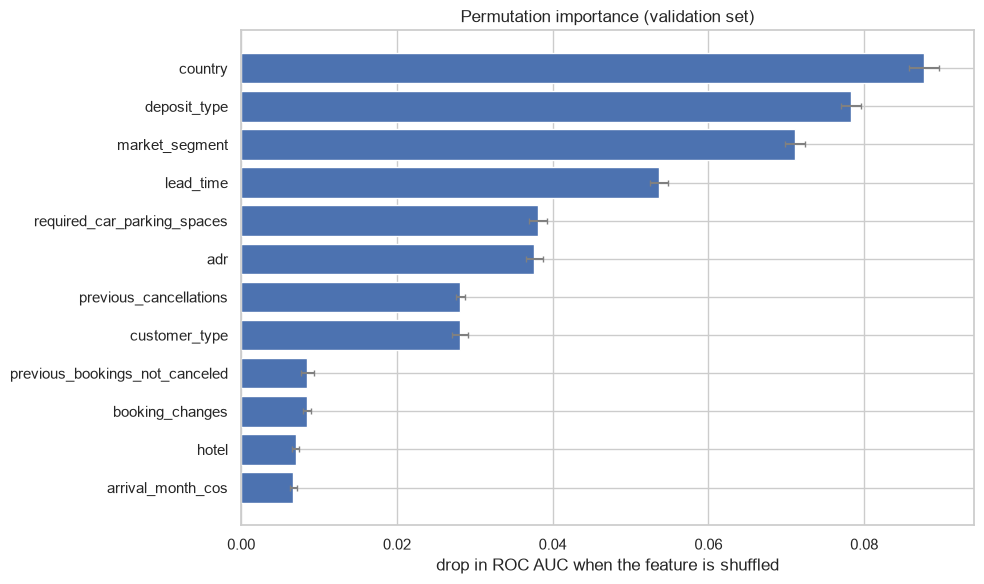

In [18]:
top = perm_frame.head(12).sort_values("importance_mean")
plt.figure(figsize=(10, 6))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"],
         color="#4C72B0", ecolor="gray", capsize=2)
plt.xlabel("drop in ROC AUC when the feature is shuffled")
plt.title("Permutation importance (validation set)")
plt.tight_layout()
plt.show()

**Reading the importances:**

1. `country` — domestic vs international bookings behave very differently.
2. `deposit_type` — the policy artefact discussed in §4.2.
3. `market_segment` — how the booking was made.
4. `lead_time` — the EDA's strongest behavioural signal.
5. `adr` — what the room cost.

`total_nights`, `total_guests` and `is_family` are much lower, which is
consistent with the EDA: party size affects *when* a booking is made rather
than *whether* it is cancelled.

## 11.1 Calibration

A model that returns probabilities has to be *calibrated*, otherwise the number is meaningless.

In [19]:
test_proba_check = winner.predict_proba(X_val)[:, 1]
bins = [0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1.01]
d = pd.DataFrame({"p": test_proba_check, "y": y_val.values})
d["bin"] = pd.cut(d["p"], bins)
cal = d.groupby("bin", observed=True).agg(
    n=("y", "size"), mean_pred=("p", "mean"), actual=("y", "mean"))
cal["gap"] = cal["actual"] - cal["mean_pred"]
print(f"overall: mean predicted {test_proba_check.mean():.4f}  actual {y_val.mean():.4f}\n")
print(cal.round(4).to_string())

overall: mean predicted 0.3673  actual 0.3704

                n  mean_pred  actual     gap
bin                                         
(0.0, 0.1]   8419     0.0208  0.0196 -0.0012
(0.1, 0.2]   2219     0.1446  0.1433 -0.0013
(0.2, 0.3]   1734     0.2491  0.2341 -0.0149
(0.3, 0.4]   1831     0.3510  0.3725  0.0215
(0.4, 0.5]   1993     0.4505  0.4446 -0.0059
(0.5, 0.6]   1553     0.5461  0.5544  0.0083
(0.6, 0.7]   1035     0.6468  0.6899  0.0431
(0.7, 0.8]    771     0.7503  0.7367 -0.0135
(0.8, 0.9]    605     0.8489  0.8876  0.0387
(0.9, 1.01]  3718     0.9930  0.9973  0.0043


## 12. Final evaluation on the untouched test set

In [20]:
final_model = build_pipeline(clone(best_model))
final_model.fit(X_train_val, y_train_val)          # refit on train + validation
test_proba = final_model.predict_proba(X_test)[:, 1]

threshold = float(best["threshold"])
test_metrics = evaluate(y_test.values, test_proba, threshold)
test_metrics["roc_auc"] = roc_auc_score(y_test, test_proba)
test_metrics["pr_auc"] = average_precision_score(y_test, test_proba)

print("test metrics:")
for k, v in test_metrics.items():
    print(f"  {k:12s} {v:.4f}")

print("\nvalidation vs test (sanity check, no overfitting):")
print(f"  ROC AUC  val {roc_auc_score(y_val, val_proba):.4f}  test {test_metrics['roc_auc']:.4f}")

test metrics:
  threshold    0.4150
  accuracy     0.8417
  precision    0.7662
  recall       0.8243
  f1           0.7942
  roc_auc      0.9312
  pr_auc       0.9009

validation vs test (sanity check, no overfitting):
  ROC AUC  val 0.9274  test 0.9312


## 13. Exporting the model

`train.py` performs exactly this procedure and writes the deployable artefacts:

```
artifacts/model.pkl              the fitted sklearn pipeline
artifacts/model_metadata.json    features, metrics, threshold, provenance
artifacts/model_comparison.csv   the CV comparison table above
artifacts/feature_importance.csv the importances above
```

Because the whole preprocessing (imputation, scaling, encoding, the country
grouping) lives *inside* the pipeline, serving only needs the raw booking
fields — there is no separate preprocessing step to keep in sync.

```bash
python train.py
```

## 14. Limitations and next steps

- **The `deposit_type` policy artefact** dominates the model. A version trained
  without it would be a better model of *guest intent*; we keep it because it is
  available at booking time and is genuinely predictive, but it means the model
  partially encodes hotel policy rather than behaviour.
- **The threshold is F1-optimal, not cost-optimal.** With a real cost matrix
  (empty room vs wasted outreach) the operating point should be chosen from
  business economics.
- **Historical data only.** Bookings from 2015-2017 in a single country; the
  lead-time effect may have shifted after the pandemic.
- **Next steps:** gradient boosting with tuned early stopping, calibration
  (isotonic) so the probabilities are trustworthy, and a time-based split to
  measure how the model degrades over time.